In [1]:
import matplotlib.pyplot as plt
import os, sys
import pickle as pkl

abspath = os.path.dirname(os.path.abspath("toast_maploader.ipynb"))
fig_out_path = "/shared_home/henachman/home/SO_PointingReqs/output_analysis"
if abspath not in sys.path:
    sys.path.append(abspath)

from toast_fbmaploader import *

In [2]:
path_to_data = "/shared_home/henachman/data/sim_outputs/"

maps_dict = {}

In [ ]:
run_path = {
    # "coadd1" : "CMB/Deep56Coadd/Deep56_1" ,
    # "coadd2" : "CMB/Deep56Coadd/Deep56_1_2" ,
    # "coadd3" : "CMB/Deep56Coadd/Deep56_1_2_3" ,
    # "coadd5" : "CMB/Deep56Coadd/Deep56_5" ,
    # "coadd1_plain" : "CMB/Deep56Coadd/Deep56_nojitter_1" ,
    # "coadd2_plain" : "CMB/Deep56Coadd/Deep56_nojitter_2" ,
    # "coadd3_plain" : "CMB/Deep56Coadd/Deep56_nojitter_3" ,
    # "coadd5_plain" : "CMB/Deep56Coadd/Deep56_nojitter_5" ,
    "BigSquare" : "CMB/Deep56Coadd/Deep56_BigSquare" ,
    }

for name, path in run_path.items():
    if name not in maps_dict:
        print(f"Adding {name}, {path}")
        I_map, _, _, hits_map, unseen_mask = load_h5_map(path, path_to_data=path_to_data)
        rot_est = get_center(I_map)
        maps_dict[name] = {"I_map": I_map,
                           "hits_map": hits_map,
                           "rot_est": rot_est,
                           "path":path}

Adding coadd5_plain, CMB/Deep56Coadd/Deep56_nojitter_5


In [18]:
N = 5000 # Num pix
pix_size = 1.0 # arcmin per pix

for map_name in ["coadd1", "coadd2", "coadd3", "coadd5", "coadd1_plain", "coadd2_plain", "coadd3_plain", "coadd5_plain"]:
        rot = get_mol_center(maps_dict[map_name]["hits_map"])

        moll_map = hp.gnomview(
                maps_dict[map_name]["I_map"],
                coord='C',
                nest=True,
                rot = rot,
                xsize=2000,
                ysize=2000,
                reso=pix_size/10,
                badcolor='gray',
                return_projected_map=True,
                no_plot=True
        )

        maps_dict[map_name]["moll_map"] = moll_map

Center of hits map: [16.06638859]°, [-1.28138353]°
Center of hits map: [16.09299325]°, [-1.30082231]°
Center of hits map: [16.11687466]°, [-1.30721887]°
Center of hits map: [16.1228354]°, [-1.28502891]°
Center of hits map: [16.06638859]°, [-1.28138353]°
Center of hits map: [16.09299325]°, [-1.30082231]°
Center of hits map: [16.11687466]°, [-1.30721887]°
Center of hits map: [16.1228354]°, [-1.28502891]°


In [19]:
def show_n_maps(maps_dict, maps_list):
    n = len(maps_list)
    fig, axs = plt.subplots(1, n, figsize=(12, 6))
    fig.subplots_adjust(wspace=0, hspace=0)
    for i, mapname in enumerate(maps_list):
        axs[i].imshow(maps_dict[mapname]["moll_map"])
        axs[i].axis('off')
        axs[i].get_yaxis().set_visible(False)
        axs[i].set_title(mapname)

    plt.suptitle(r"Simulated Planck $C_\ell$-like Map")
    fig.subplots_adjust(wspace=0, hspace=0)


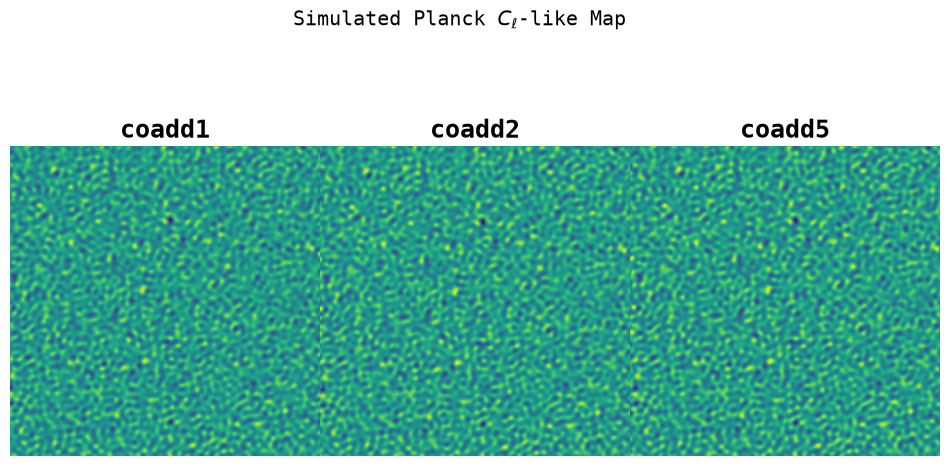

In [20]:
show_n_maps(maps_dict, ["coadd1", "coadd2", "coadd5"])

In [21]:
N = np.shape(maps_dict["coadd1"]["moll_map"])[0]
print(N)
window = (cosine_window(N))

apodization_dict = {}

for map_name in ["coadd1", "coadd2", "coadd3", "coadd5", "coadd1_plain", "coadd2_plain", "coadd3_plain", "coadd5_plain"]:
  apodized_map = window * maps_dict[map_name]["moll_map"]
  apodization_dict[map_name] = apodized_map

2000


Day 1 Auto PS

In [22]:
delta_ell = 25.
# ell_min = 100.
ell_max = 5000.

ps_dict = {}
for i, map_name in enumerate(["coadd1", "coadd2", "coadd3", "coadd5", "coadd1_plain", "coadd2_plain", "coadd3_plain", "coadd5_plain"]):
    binned_ell, binned_spectrum = calculate_2d_spectrum(apodization_dict[map_name],apodization_dict[map_name],delta_ell,ell_max,0.5,N)
    # to go from Cl to Dl
    fac_binned = binned_ell * (binned_ell+1.) /2. / np.pi
    ps_dict[map_name]= {"binned_ell": binned_ell,
                        "spectrum": binned_spectrum* fac_binned}

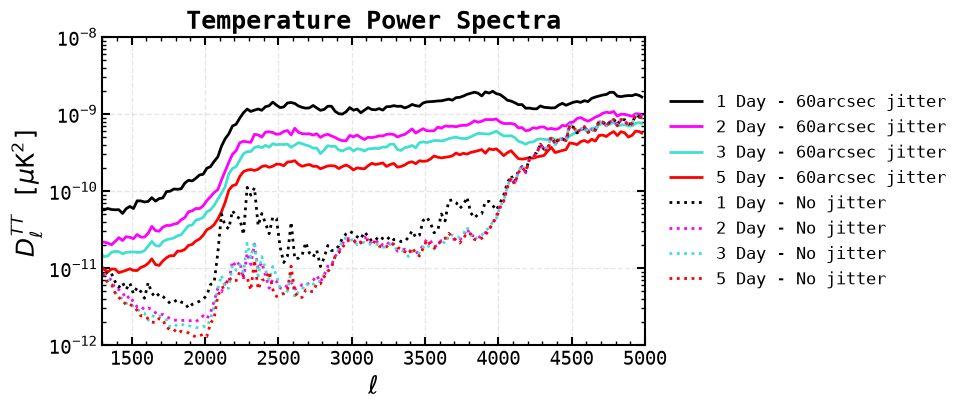

In [35]:
fig, ax = plt.subplots(figsize=(7, 4))
labels = ["1 Day - 60arcsec jitter", "2 Day - 60arcsec jitter", "3 Day - 60arcsec jitter", "5 Day - 60arcsec jitter", "1 Day - No jitter", "2 Day - No jitter", "3 Day - No jitter", "5 Day - No jitter"]
colors = ['black', 'magenta', 'turquoise', 'red', 'black', 'magenta', 'turquoise', 'red']
styles = ['-', '-', '-', '-', ':', ':', ':', ':']
for i, map_name in enumerate(["coadd1", "coadd2", "coadd3", "coadd5", "coadd1_plain", "coadd2_plain", "coadd3_plain", "coadd5_plain"]):
    # to go from Cl to Dl        
    ax.plot(ps_dict[map_name]["binned_ell"],ps_dict[map_name]["spectrum"], label=labels[i], color=colors[i], linestyle=styles[i])


ax.set_ylabel(r'$D^{TT}_{\ell}$ [$\mu$K$^2$]', fontsize=18)
ax.set_xlabel(r'$\ell$', fontsize=18)
ax.set_yscale("log")
# ax.set_xscale("log")
ax.set_xlim(1300, 5000)
ax.set_ylim(1e-12,1e-8)
plt.title("Temperature Power Spectra")
ax.legend(fontsize=12, bbox_to_anchor=(1.3,0.5), loc='center')

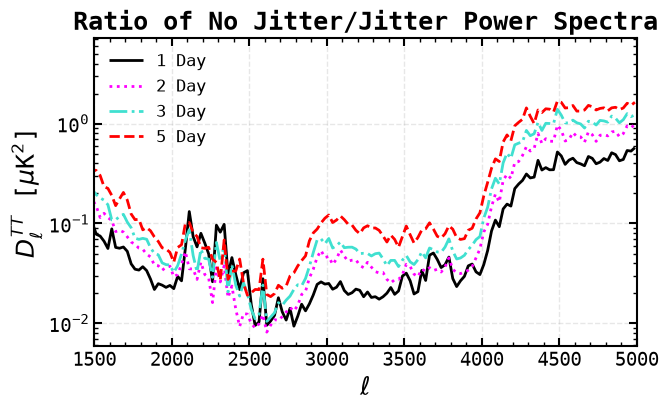

In [24]:
fig, ax = plt.subplots(figsize=(7, 4))
labels = ["1 Day", "2 Day", "3 Day", "5 Day"]
colors = ['black', 'magenta', 'turquoise', 'red']
styles = ['-', ':', "-.", "--"]
ax.plot(ps_dict["coadd1"]["binned_ell"],ps_dict["coadd1_plain"]["spectrum"]/ps_dict["coadd1"]["spectrum"], label=labels[0], color=colors[0], linestyle=styles[0])
ax.plot(ps_dict["coadd2"]["binned_ell"],ps_dict["coadd2_plain"]["spectrum"]/ps_dict["coadd2"]["spectrum"], label=labels[1], color=colors[1], linestyle=styles[1])
ax.plot(ps_dict["coadd3"]["binned_ell"],ps_dict["coadd3_plain"]["spectrum"]/ps_dict["coadd3"]["spectrum"], label=labels[2], color=colors[2], linestyle=styles[2])
ax.plot(ps_dict["coadd5"]["binned_ell"],ps_dict["coadd5_plain"]["spectrum"]/ps_dict["coadd5"]["spectrum"], label=labels[3], color=colors[3], linestyle=styles[3])


# print(ps_dict["coadd1_plain"]["spectrum"]-ps_dict["coadd1"]["spectrum"])
ax.set_ylabel(r'$D^{TT}_{\ell}$ [$\mu$K$^2$]', fontsize=18)
ax.set_xlabel(r'$\ell$', fontsize=18)
ax.set_yscale("log")
# ax.set_xscale("log")
ax.set_xlim(1500, 5000)
plt.title("Ratio of No Jitter/Jitter Power Spectra")
ax.legend(fontsize=12)